# 01 — Tạo vector khuôn mặt
**Dự án:** Nhận diện khuôn mặt qua camera và chào hỏi theo tên

**Ý tưởng:**
```
Ảnh  →  tách khuôn mặt (làm 1 lần)  →  mỗi model biến khuôn mặt thành 1 vector
```

**Input:**
- `<tài khoản>/face-data-index` (tạo ở notebook 00)
- LFW: `jessicali9530/lfw-dataset`
- CPLFW: `devvindan/crosspose-lfw-database-cplfw`

**Output:** Kaggle Dataset `<tài khoản>/face-vectors`
```
face-vectors/
├── images.csv        ← danh sách ảnh đã dùng, dòng thứ i ứng với vector thứ i
├── ArcFace.npy
├── SFace.npy
├── Facenet512.npy
└── VGG-Face.npy
```

> Bật **GPU** và **Internet** (để tải model lần đầu) trong phần Settings của notebook.

## Bước 1: Cấu hình

In [1]:
import os

# ==== ĐƯỜNG DẪN ====
LFW_CSV    = '/kaggle/input/datasets/minhbodoi/face-data-index/lfw.csv'
PAIRS_CSV  = '/kaggle/input/datasets/minhbodoi/face-data-index/cplfw_pairs.csv'
OUTPUT_DIR = '/kaggle/working/face-vectors'
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHAY_THU = False   # True: chỉ lấy 100 ảnh để thử nhanh (CPU), không đẩy dataset. False: chạy đủ (nên dùng GPU)

MODELS   = ['ArcFace', 'SFace', 'Facenet512', 'VGG-Face']
DETECTOR = 'retinaface'   # bộ tìm khuôn mặt, chính xác nhất trong deepface

# Chọn ảnh LFW
N_KNOWN     = 10    # số người "quen" (sẽ được đăng ký ở notebook 02)
MAX_PER_KNOWN = 20  # tối đa số ảnh mỗi người quen
N_STRANGERS = 300   # số người lạ, mỗi người 1 ảnh
SEED = 42

for p in [LFW_CSV, PAIRS_CSV]:
    print('OK   ' if os.path.exists(p) else 'SAI  ', p)

# Nếu SAI: in các file đang có trong input để tìm đúng đường dẫn
if not all(os.path.exists(p) for p in [LFW_CSV, PAIRS_CSV]):
    for cur, dirs, files in os.walk('/kaggle/input'):
        if any(f.endswith('.csv') for f in files):
            print(cur, [f for f in files if f.endswith('.csv')])
        if len(dirs) > 20:
            dirs[:] = []

OK    /kaggle/input/datasets/minhbodoi/face-data-index/lfw.csv
OK    /kaggle/input/datasets/minhbodoi/face-data-index/cplfw_pairs.csv


## Bước 2: Cài thư viện

In [2]:
# 2 dòng này PHẢI chạy trước khi nạp tensorflow (nếu đã lỡ nạp: Run > Restart rồi chạy lại từ đầu)
os.environ['TF_USE_LEGACY_KERAS'] = '1'    # dùng Keras cũ (tf-keras), bộ tìm mặt retinaface cần cái này
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # ẩn các dòng thông báo của TensorFlow (vd: cuInit khi chạy CPU)
import tensorflow as tf
TF_VER = '.'.join(tf.__version__.split('.')[:2])   # vd: 2.18
# cài tf-keras đúng phiên bản TensorFlow sẵn có, để không làm hỏng GPU
!pip install -q deepface "tf-keras=={TF_VER}.*"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deepface import DeepFace
from tqdm.auto import tqdm

# Tự dùng GPU nếu có, không có thì chạy CPU
print('Đang chạy trên:', 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU (chậm hơn)')

# Kiểm tra TensorFlow đang dùng Keras cũ (tf_keras), nếu không bộ tìm mặt sẽ lỗi ở Bước 4
keras_dang_dung = tf.keras.layers.Layer.__module__.split('.')[0]
print('Keras đang dùng:', keras_dang_dung)
assert keras_dang_dung == 'tf_keras', 'Sai Keras! Vào Run > Restart & Clear Cell Outputs, rồi chạy lại từ Bước 1.'

26-10-28 21:48:09 - Directory /root/.deepface has been created
26-10-28 21:48:09 - Directory /root/.deepface/weights has been created
Đang chạy trên: GPU
Keras đang dùng: tf_keras


## Bước 3: Chọn ảnh
- **LFW:** 10 người quen (chọn ngẫu nhiên trong số người có >= 10 ảnh) và 300 người lạ (mỗi người 1 ảnh)
- **CPLFW:** tất cả ảnh xuất hiện trong 6.000 cặp

In [3]:
lfw   = pd.read_csv(LFW_CSV)
pairs = pd.read_csv(PAIRS_CSV)

# LFW: người quen
counts = lfw.person.value_counts()
known_people = counts[counts >= 10].sample(N_KNOWN, random_state=SEED).index
known = lfw[lfw.person.isin(known_people)].groupby('person').head(MAX_PER_KNOWN)
known = known.assign(source='lfw', group='known')

# LFW: người lạ
other_people = pd.Series(counts.index.difference(known_people))
stranger_people = other_people.sample(N_STRANGERS, random_state=SEED)
strangers = lfw[lfw.person.isin(stranger_people)].groupby('person').head(1)
strangers = strangers.assign(source='lfw', group='stranger')

# CPLFW: mọi ảnh có trong danh sách cặp (tên file dạng Ten_Nguoi_1.jpg)
cplfw_paths = pd.unique(pd.concat([pairs.path_1, pairs.path_2]))
cplfw = pd.DataFrame({'path': cplfw_paths})
cplfw['person'] = cplfw.path.map(lambda p: os.path.basename(p).rsplit('_', 1)[0])
cplfw = cplfw.assign(source='cplfw', group='pair')

images = pd.concat([known, strangers, cplfw], ignore_index=True)[['source', 'group', 'person', 'path']]
if CHAY_THU:
    images = images.sample(100, random_state=SEED).reset_index(drop=True)
    print('CHẠY THỬ: chỉ lấy 100 ảnh\n')

print('Người quen:', ', '.join(known_people))
print()
print(images.groupby(['source', 'group']).agg(so_anh=('path', 'size'), so_nguoi=('person', 'nunique')))
print(f'\nTổng: {len(images):,} ảnh')

Người quen: Sergey_Lavrov, Tiger_Woods, Catherine_Zeta-Jones, Mohammad_Khatami, Andy_Roddick, Kofi_Annan, James_Blake, Roger_Federer, Nancy_Pelosi, Nicanor_Duarte_Frutos

                 so_anh  so_nguoi
source group                     
cplfw  pair        5984      2296
lfw    known        141        10
       stranger     300       300

Tổng: 6,425 ảnh


## Bước 4: Tách khuôn mặt (làm 1 lần, dùng chung cho mọi model)
Nếu không tìm thấy mặt, deepface trả về nguyên ảnh với độ tin cậy = 0. Những ảnh đó được đánh dấu `face_found = False`.
Nếu ảnh có nhiều mặt, lấy mặt **gần tâm ảnh nhất**: LFW và CPLFW luôn đặt người được gắn tên ở giữa ảnh.
(Bản trước lấy mặt to nhất, nên có lúc lấy nhầm mặt bị cắt ở mép ảnh.)

In [4]:
from PIL import Image

def gan_tam(r, W, H):
    a = r['facial_area']
    return (a['x'] + a['w'] / 2 - W / 2) ** 2 + (a['y'] + a['h'] / 2 - H / 2) ** 2

faces, found, n_mat = [], [], []
for p in tqdm(images.path, desc='Tách mặt'):
    W, H = Image.open(p).size
    res = DeepFace.extract_faces(p, detector_backend=DETECTOR, enforce_detection=False,
                                 color_face='bgr', normalize_face=False)
    best = min(res, key=lambda r: gan_tam(r, W, H))
    faces.append(best['face'].astype('uint8'))
    found.append(best['confidence'] > 0)
    n_mat.append(len(res))

images['face_found'] = found
print(f'Không tìm thấy mặt: {(~images.face_found).sum()} / {len(images)} ảnh')
print(f'Ảnh có nhiều mặt  : {sum(n > 1 for n in n_mat)} / {len(images)} ảnh')
print(images.groupby('source').face_found.mean().map('{:.1%}'.format).rename('tỉ lệ tìm thấy mặt'))

Tách mặt:   0%|          | 0/6425 [00:00<?, ?it/s]

I0000 00:00:1793224093.898356      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793224093.901941      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


26-10-28 21:48:16 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5

  0%|          | 0.00/119M [00:00<?, ?B/s]
  3%|▎         | 3.15M/119M [00:00<00:03, 30.2MB/s]
  9%|▉         | 11.0M/119M [00:00<00:02, 41.6MB/s]
 18%|█▊        | 21.5M/119M [00:00<00:01, 57.1MB/s]
 25%|██▍       | 29.4M/119M [00:00<00:01, 53.4MB/s]
 30%|██▉       | 35.1M/119M [00:00<00:02, 36.5MB/s]
 36%|███▌      | 43.0M/119M [00:00<00:01, 45.2MB/s]
 45%|████▍     | 53.0M/119M [00:01<00:01, 56.2MB/s]
 53%|█████▎    | 63.4M/119M [00:01<00:00, 65.5MB/s]
 64%|██████▎   | 75.5M/119M [00:01<00:00, 79.2MB/s]
 71%|███████   | 84.4M/119M [00:01<00:00, 78.7MB/s]
 79%|███████▊  | 93.3M/119M [00:01<00:00, 63.7MB/s]
 85%|████████▍ | 101M/119M [00:01<00:00, 42.8MB/s] 
 90%|████████▉ | 106M/119M [00:02<00:00, 44.4MB/s]
100%|██████████| 119M/119M [00:02<00:00, 54.7MB/s]


Không tìm thấy mặt: 18 / 6425 ảnh
Ảnh có nhiều mặt  : 751 / 6425 ảnh
source
cplfw     99.7%
lfw      100.0%
Name: tỉ lệ tìm thấy mặt, dtype: object


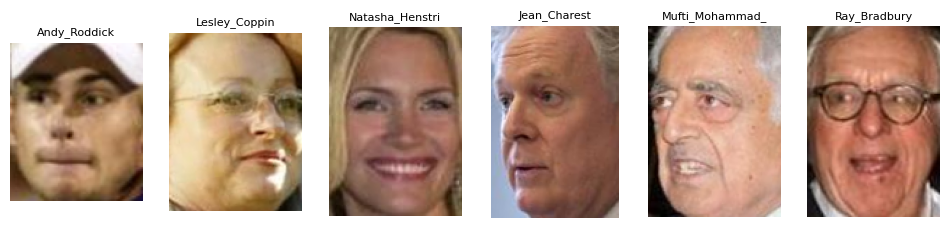

In [5]:
# Xem thử 6 khuôn mặt đã tách
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, i in zip(axes, np.linspace(0, len(faces) - 1, 6).astype(int)):
    ax.imshow(faces[i][:, :, ::-1]); ax.axis('off')   # BGR -> RGB để hiển thị
    ax.set_title(images.person[i][:15], fontsize=8)
plt.show()

## Bước 5: Tạo vector cho từng model
Lần đầu mỗi model sẽ tải trọng số về. Model nào đã chạy xong (đã có file `.npy`) sẽ được bỏ qua nếu chạy lại.

In [6]:
for model in MODELS:
    out = f'{OUTPUT_DIR}/{model}.npy'
    # chỉ bỏ qua khi file cũ khớp đúng số ảnh lần này (tránh dùng nhầm file của lần chạy thử)
    if os.path.exists(out) and len(np.load(out)) == len(faces):
        print(f'{model}: đã có, bỏ qua'); continue

    t0, vecs = time.time(), []
    for face in tqdm(faces, desc=model):
        r = DeepFace.represent(face, model_name=model, detector_backend='skip', enforce_detection=False)
        vecs.append(r[0]['embedding'])
    vecs = np.array(vecs, dtype=np.float32)
    np.save(out, vecs)
    print(f'{model}: {vecs.shape} | {(time.time() - t0) / len(faces) * 1000:.0f} ms/ảnh')

ArcFace:   0%|          | 0/6425 [00:00<?, ?it/s]

26-10-28 22:03:47 - 🔗 arcface_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5 to /root/.deepface/weights/arcface_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5
To: /root/.deepface/weights/arcface_weights.h5

  0%|          | 0.00/137M [00:00<?, ?B/s]
  2%|▏         | 3.15M/137M [00:00<00:04, 28.2MB/s]
  8%|▊         | 11.0M/137M [00:00<00:03, 39.8MB/s]
 16%|█▌        | 21.5M/137M [00:00<00:02, 55.8MB/s]
 23%|██▎       | 32.0M/137M [00:00<00:01, 64.8MB/s]
 31%|███       | 42.5M/137M [00:00<00:01, 48.3MB/s]
 39%|███▊      | 53.0M/137M [00:00<00:01, 56.9MB/s]
 46%|████▋     | 63.4M/137M [00:01<00:01, 63.9MB/s]
 54%|█████▍    | 73.9M/137M [00:01<00:00, 69.5MB/s]
 62%|██████▏   | 84.4M/137M [00:01<00:00, 74.5MB/s]
 69%|██████▉   | 94.9M/137M [00:01<00:00, 77.5MB/s]
 77%|███████▋  | 105M/137M [00:01<00:00, 74.3MB/s] 
 85%|████████▍ | 116M/137M [00:01<00:00, 78.3MB/s]
 92%|█████████▏| 126M/137M [00:01<00:00, 78.0MB/s]
100%|██████████| 137M/137M [00:02<00:00, 68.3MB/s]


ArcFace: (6425, 512) | 107 ms/ảnh


SFace:   0%|          | 0/6425 [00:00<?, ?it/s]

26-10-28 22:15:13 - 🔗 face_recognition_sface_2021dec.onnx will be downloaded from https://github.com/opencv/opencv_zoo/raw/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx to /root/.deepface/weights/face_recognition_sface_2021dec.onnx...


... (6 outputs left out)

VGG-Face:   0%|          | 0/6425 [00:00<?, ?it/s]

26-10-28 22:44:41 - 🔗 vgg_face_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5 to /root/.deepface/weights/vgg_face_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5
To: /root/.deepface/weights/vgg_face_weights.h5

  0%|          | 0.00/580M [00:00<?, ?B/s]
  1%|          | 3.15M/580M [00:00<00:18, 31.3MB/s]
  2%|▏         | 9.44M/580M [00:00<00:11, 48.7MB/s]
  3%|▎         | 14.7M/580M [00:00<00:15, 37.0MB/s]
  4%|▎         | 20.4M/580M [00:00<00:13, 42.6MB/s]
  4%|▍         | 25.2M/580M [00:00<00:13, 39.8MB/s]
  6%|▌         | 32.0M/580M [00:00<00:13, 39.6MB/s]
  6%|▋         | 37.2M/580M [00:00<00:12, 42.8MB/s]
  7%|▋         | 42.5M/580M [00:01<00:14, 36.7MB/s]
  8%|▊         | 47.2M/580M [00:01<00:13, 38.1MB/s]
  9%|▉         | 51.4M/580M [00:01<00:14, 35.8MB/s]
 10%|▉         | 55.6M/580M [00:01<00:16, 31.3MB/s]
 10%|█         | 59.8M/580M [00:01<00:15, 33.1MB/s]
 11%|█         | 63.4M/580M [00:01<00:17, 28.9MB/s]
 12%|█▏        | 68.2M/580M [00:01<00:15, 32.7MB/s]
 13%|█▎        | 73.4M/580M [00:02<00:13, 36.8MB/s]
 13%|█▎        | 77.

VGG-Face: (6425, 4096) | 27 ms/ảnh


## Bước 6: Lưu danh sách ảnh

In [7]:
images.to_csv(f'{OUTPUT_DIR}/images.csv', index=False)
print(f'Đã lưu images.csv ({len(images):,} dòng) và {len(MODELS)} file vector')

Đã lưu images.csv (6,425 dòng) và 4 file vector


## Bước 7: Tạo Kaggle Dataset

In [ ]:
# Tự động lưu kết quả thành Kaggle Dataset (Private)
import json, subprocess

dataset_name = os.path.basename(OUTPUT_DIR)
kaggle_user  = [l.split(':')[1].strip() for l in
                subprocess.run('kaggle config view', shell=True,
                               capture_output=True, text=True)
                .stdout.split('\n') if 'username' in l][0]

with open(f'{OUTPUT_DIR}/dataset-metadata.json', 'w') as f:
    json.dump({
        'title'   : dataset_name,
        'id'      : f'{kaggle_user}/{dataset_name}',
        'licenses': [{'name': 'CC0-1.0'}]
    }, f)

check = subprocess.run(f'kaggle datasets list --user {kaggle_user} --search {dataset_name}',
                       shell=True, capture_output=True, text=True)
if CHAY_THU:
    print('CHẠY THỬ: không đẩy dataset. Đổi CHAY_THU = False ở Bước 1 để chạy thật.')
elif dataset_name in check.stdout:
    os.system(f'kaggle datasets version -p {OUTPUT_DIR} -m "update"')
    print(f'Done! {kaggle_user}/{dataset_name}')
else:
    os.system(f'kaggle datasets create -p {OUTPUT_DIR}')
    print(f'Done! {kaggle_user}/{dataset_name}')

Starting upload for file VGG-Face.npy


100%|██████████| 100M/100M [00:03<00:00, 29.0MB/s] 
  0%|          | 0.00/808k [00:00<?, ?B/s]

Upload successful: VGG-Face.npy (100MB)
Starting upload for file images.csv


100%|██████████| 808k/808k [00:00<00:00, 865kB/s]
  0%|          | 0.00/3.14M [00:00<?, ?B/s]

Upload successful: images.csv (808KB)
Starting upload for file SFace.npy


100%|██████████| 3.14M/3.14M [00:01<00:00, 2.72MB/s]
  0%|          | 0.00/12.5M [00:00<?, ?B/s]

Upload successful: SFace.npy (3MB)
Starting upload for file Facenet512.npy


100%|██████████| 12.5M/12.5M [00:01<00:00, 6.88MB/s]


Upload successful: Facenet512.npy (13MB)
Starting upload for file ArcFace.npy


100%|██████████| 12.5M/12.5M [00:01<00:00, 8.99MB/s]


Upload successful: ArcFace.npy (13MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/minhbodoi/face-vectors
Done! minhbodoi/face-vectors
